In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

import joblib

# BLOCK 1. Loading the dataset into Notebook

# Task 1. Load the dataset

In [6]:
df = pd.read_csv("E:/Python/delivery_eta_project/data/processed/final_ml_dataset.csv")
df

,order_id,distance_km,items_count,order_amount,weather,traffic_level,order_ts,delivery_minutes,date,restaurant_id,...,restaurant_previous_orders_count,restaurant_historical_avg_delivery,courier_previous_orders_count,courier_historical_avg_delivery,is_peak_hour,month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
0,1493,5.63,4,5.53,rain,medium,2026-01-01 00:00:00,42.5,2026-01-01,53,...,0,NaN,0,NaN,False,1,0.000000,1.000000,-0.433884,-0.900969
1,4693,5.12,1,27.99,cloudy,low,2026-01-01 01:00:00,36.3,2026-01-01,3,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
2,7374,2.27,8,17.60,clear,low,2026-01-01 01:00:00,17.9,2026-01-01,5,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
3,8650,2.43,4,5.00,cloudy,medium,2026-01-01 01:00:00,40.1,2026-01-01,54,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
4,3416,1.90,8,23.10,rain,medium,2026-01-01 02:00:00,41.9,2026-01-01,13,...,0,NaN,0,NaN,False,1,0.500000,0.866025,-0.433884,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9600,7.68,4,19.54,cloudy,low,2026-06-29 22:00:00,48.6,2026-06-29,34,...,143,46.565734,91,43.406593,False,6,-0.500000,0.866025,0.781831,0.623490
9996,832,0.81,2,5.00,clear,low,2026-06-29 23:00:00,12.9,2026-06-29,42,...,131,46.692366,96,41.589583,False,6,-0.258819,0.965926,0.781831,0.623490
9997,6190,5.33,3,14.28,rain,low,2026-06-29 23:00:00,41.0,2026-06-29,74,...,104,45.194231,85,39.550588,False,6,-0.258819,0.965926,0.781831,0.623490
9998,5113,16.85,8,7.53,clear,high,2026-06-30 00:00:00,88.2,2026-06-30,35,...,133,44.308271,80,42.710000,False,6,0.000000,1.000000,0.974928,-0.222521


# Task 2. Sort the dataset by time

In [7]:
df = df.sort_values(by="order_ts").reset_index(drop=True)

# BLOCK 2. Initial ML Profiling

# Task 3. Check data structure

In [8]:
df.head()

,order_id,distance_km,items_count,order_amount,weather,traffic_level,order_ts,delivery_minutes,date,restaurant_id,...,restaurant_previous_orders_count,restaurant_historical_avg_delivery,courier_previous_orders_count,courier_historical_avg_delivery,is_peak_hour,month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
0,1493,5.63,4,5.53,rain,medium,2026-01-01 00:00:00,42.5,2026-01-01,53,...,0,NaN,0,NaN,False,1,0.000000,1.000000,-0.433884,-0.900969
1,4693,5.12,1,27.99,cloudy,low,2026-01-01 01:00:00,36.3,2026-01-01,3,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
2,7374,2.27,8,17.60,clear,low,2026-01-01 01:00:00,17.9,2026-01-01,5,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
3,8650,2.43,4,5.00,cloudy,medium,2026-01-01 01:00:00,40.1,2026-01-01,54,...,0,NaN,0,NaN,True,1,0.258819,0.965926,-0.433884,-0.900969
4,3416,1.90,8,23.10,rain,medium,2026-01-01 02:00:00,41.9,2026-01-01,13,...,0,NaN,0,NaN,False,1,0.500000,0.866025,-0.433884,-0.900969


In [9]:
df.tail()

,order_id,distance_km,items_count,order_amount,weather,traffic_level,order_ts,delivery_minutes,date,restaurant_id,...,restaurant_previous_orders_count,restaurant_historical_avg_delivery,courier_previous_orders_count,courier_historical_avg_delivery,is_peak_hour,month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
9995,9600,7.68,4,19.54,cloudy,low,2026-06-29 22:00:00,48.6,2026-06-29,34,...,143,46.565734,91,43.406593,False,6,-0.500000,0.866025,0.781831,0.623490
9996,832,0.81,2,5.00,clear,low,2026-06-29 23:00:00,12.9,2026-06-29,42,...,131,46.692366,96,41.589583,False,6,-0.258819,0.965926,0.781831,0.623490
9997,6190,5.33,3,14.28,rain,low,2026-06-29 23:00:00,41.0,2026-06-29,74,...,104,45.194231,85,39.550588,False,6,-0.258819,0.965926,0.781831,0.623490
9998,5113,16.85,8,7.53,clear,high,2026-06-30 00:00:00,88.2,2026-06-30,35,...,133,44.308271,80,42.710000,False,6,0.000000,1.000000,0.974928,-0.222521
9999,6047,1.24,5,50.09,rain,medium,2026-06-30 00:00:00,34.3,2026-06-30,48,...,113,41.499115,84,46.254762,False,6,0.000000,1.000000,0.974928,-0.222521


In [10]:
df.shape

(10000, 32)

In [11]:
df.columns

Index(['order_id', 'distance_km', 'items_count', 'order_amount', 'weather',
       'traffic_level', 'order_ts', 'delivery_minutes', 'date',
       'restaurant_id', 'avg_prep_minutes', 'restaurant_rating', 'avg_temp_c',
       'rain_mm', 'snow_cm', 'courier_id', 'vehicle', 'experience_months',
       'courier_rating', 'order_hour', 'day_of_week', 'is_weekend',
       'restaurant_previous_orders_count',
       'restaurant_historical_avg_delivery', 'courier_previous_orders_count',
       'courier_historical_avg_delivery', 'is_peak_hour', 'month', 'hour_sin',
       'hour_cos', 'day_of_week_sin', 'day_of_week_cos'],
      dtype='str')

In [12]:
df.dtypes

order_id                                int64
distance_km                           float64
items_count                             int64
order_amount                          float64
weather                                   str
traffic_level                             str
order_ts                                  str
delivery_minutes                      float64
date                                      str
restaurant_id                           int64
avg_prep_minutes                      float64
restaurant_rating                     float64
avg_temp_c                            float64
rain_mm                               float64
snow_cm                               float64
courier_id                              int64
vehicle                                   str
experience_months                       int64
courier_rating                        float64
order_hour                              int64
day_of_week                             int64
is_weekend                        

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   order_id                            10000 non-null  int64  
 1   distance_km                         10000 non-null  float64
 2   items_count                         10000 non-null  int64  
 3   order_amount                        10000 non-null  float64
 4   weather                             10000 non-null  str    
 5   traffic_level                       10000 non-null  str    
 6   order_ts                            10000 non-null  str    
 7   delivery_minutes                    10000 non-null  float64
 8   date                                10000 non-null  str    
 9   restaurant_id                       10000 non-null  int64  
 10  avg_prep_minutes                    10000 non-null  float64
 11  restaurant_rating                   10000 non-null  f

# Task 4. Identify datetime columns

In [14]:
df["order_ts"] = pd.to_datetime(df["order_ts"])
df["date"] = pd.to_datetime(df["date"])

# Task 5. Identify numeric, categorical and boolean features

In [15]:
num_cols = df.drop(columns=["order_id", "delivery_minutes"]).select_dtypes(include="number").columns
bool_cols = df.select_dtypes(include="bool").columns
datetime_cols = df.select_dtypes(include="datetime").columns
cat_cols = df.select_dtypes(exclude=["number", "boolean", "datetime"]).columns
print("Numeric:", list(num_cols))
print("Boolean:", list(bool_cols))
print("Datetime:", list(datetime_cols))
print("Categorical:", list(cat_cols))

Numeric: ['distance_km', 'items_count', 'order_amount', 'restaurant_id', 'avg_prep_minutes', 'restaurant_rating', 'avg_temp_c', 'rain_mm', 'snow_cm', 'courier_id', 'experience_months', 'courier_rating', 'order_hour', 'day_of_week', 'restaurant_previous_orders_count', 'restaurant_historical_avg_delivery', 'courier_previous_orders_count', 'courier_historical_avg_delivery', 'month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']
Boolean: ['is_weekend', 'is_peak_hour']
Datetime: ['order_ts', 'date']
Categorical: ['weather', 'traffic_level', 'vehicle']


# Task 6. Check missing values

In [16]:
df.isna().sum() # Only historical averages

order_id                                0
distance_km                             0
items_count                             0
order_amount                            0
weather                                 0
traffic_level                           0
order_ts                                0
delivery_minutes                        0
date                                    0
restaurant_id                           0
avg_prep_minutes                        0
restaurant_rating                       0
avg_temp_c                              0
rain_mm                                 0
snow_cm                                 0
courier_id                              0
vehicle                                 0
experience_months                       0
courier_rating                          0
order_hour                              0
day_of_week                             0
is_weekend                              0
restaurant_previous_orders_count        0
restaurant_historical_avg_delivery

# Task 7. Check duplicate values

In [17]:
df.duplicated().sum()

np.int64(0)

# BLOCK 3.Target Analysis

# Task 8. Target statistics

In [18]:
df["delivery_minutes"].min()

np.float64(8.0)

In [19]:
df["delivery_minutes"].max()

np.float64(107.9)

In [20]:
df["delivery_minutes"].mean()

np.float64(42.7873)

In [21]:
df["delivery_minutes"].median()

np.float64(41.8)

In [22]:
df["delivery_minutes"].std()

np.float64(13.419665996348245)

In [23]:
p_25 = np.percentile(df.delivery_minutes, 25)
p_50 = np.percentile(df.delivery_minutes, 50)
p_75 = np.percentile(df.delivery_minutes, 75)
p_95 = np.percentile(df.delivery_minutes, 95)
p_99 = np.percentile(df.delivery_minutes, 99)
print(f"25-th percentile: {p_25}")
print(f"50-th percentile: {p_50}")
print(f"75-th percentile: {p_75}")
print(f"95-th percentile: {p_95}")
print(f"99-th percentile: {p_99}")

25-th percentile: 33.2
50-th percentile: 41.8
75-th percentile: 51.1
95-th percentile: 66.6
99-th percentile: 78.8


# Task 9. Target distribution

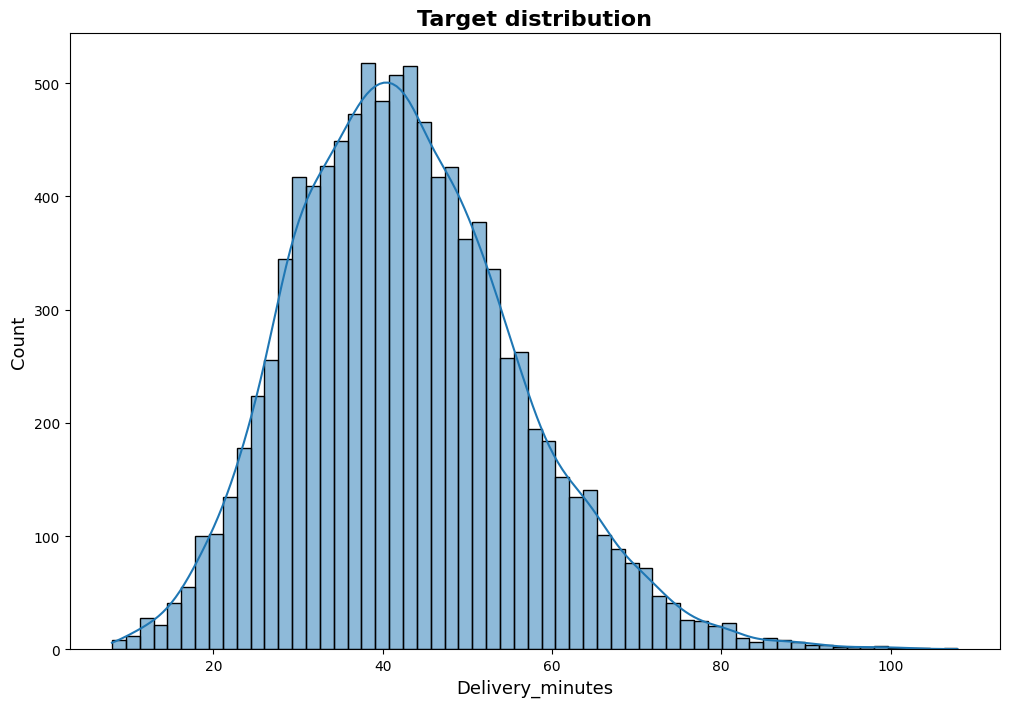

In [24]:
plt.figure(figsize= (12, 8))
sns.histplot(df["delivery_minutes"], kde=True)

plt.title("Target distribution", fontsize= 16, fontweight= "bold")
plt.xlabel("Delivery_minutes", fontsize= 13)
plt.ylabel("Count", fontsize= 13)

plt.show()

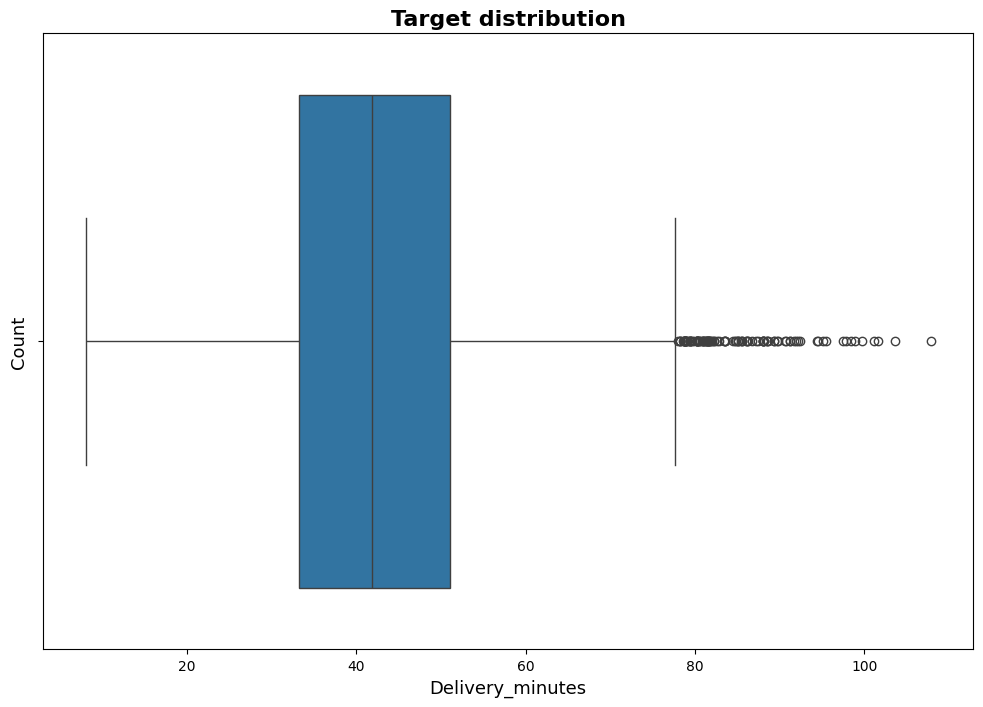

In [25]:
plt.figure(figsize= (12, 8))
sns.boxplot(x=df["delivery_minutes"])

plt.title("Target distribution", fontsize= 16, fontweight= "bold")
plt.xlabel("Delivery_minutes", fontsize= 13)
plt.ylabel("Count", fontsize= 13)

plt.show()

# BLOCK 4. Feature Engineering

# Task 10. Month

In [26]:
df["month"] = df["order_ts"].dt.month

# Task 11. Hour cyclical encoding

In [27]:
df["hour_sin"] = np.sin(2 * np.pi * df["order_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["order_hour"] / 24)

# Task 12. Day-of-week cyclical encoding

In [28]:
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

# BLOCK 5. Time-based Split

# Task 13. Perform time-based split

In [29]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

# Task 14. check for the absence of temporal leakage

In [30]:
print(train_df["order_ts"].max() <= val_df["order_ts"].min())
print(val_df["order_ts"].max() <= test_df["order_ts"].min())

True
True


# Task 15. Create train/validation/test features and target

In [84]:
# drop datetime columns, using new features instead (month, hour_sin, hour_cos, day_of_week_sin, day_of_week_cos)  

X_train = train_df.drop(columns=["order_id", "restaurant_id", "courier_id", "delivery_minutes", "order_ts", "date"]) 
y_train = train_df["delivery_minutes"]

X_val = val_df.drop(columns=["order_id", "restaurant_id", "courier_id", "delivery_minutes", "order_ts", "date"])
y_val = val_df["delivery_minutes"]

X_test = test_df.drop(columns=["order_id", "restaurant_id", "courier_id", "delivery_minutes", "order_ts", "date"])
y_test = test_df["delivery_minutes"]

# BLOCK 6. Baseline

# Task 16. Calculate median baseline

In [85]:
baseline_value = y_train.median()

# Task 17. Calculate baseline metrics

In [86]:
baseline_preds = np.full(shape=len(y_val), fill_value=baseline_value)

baseline_RMSE = root_mean_squared_error(y_val, baseline_preds)
baseline_MAE = mean_absolute_error(y_val, baseline_preds)
baseline_r2 = r2_score(y_val, baseline_preds)
baseline_MAPE = mean_absolute_percentage_error(y_val, baseline_preds) * 100

baseline_metrics = pd.DataFrame({
    "root_mean_squared_error": baseline_RMSE,
    "mean_absolute_error": baseline_MAE,
    "r2_score": baseline_r2,
    "mean_absolute_percentage_error": baseline_MAPE
}, index= ["Baseline"])
baseline_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Baseline,13.602701,10.755933,-0.008319,27.743731


# BLOCK 7. Linear Regression

# Task 18. Build and train Linear Regression pipeline

In [87]:
num_cols = X_train.select_dtypes(include="number").columns
bool_cols = X_train.select_dtypes(include="bool").columns
cat_cols = X_train.select_dtypes(exclude=["number", "bool", "datetime"]).columns

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num_cols', num_transformer, num_cols),
    ('cat_cols', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols),
    ('bool_cols', 'passthrough', bool_cols)
    
])
lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

In [88]:
lr_preds = lr.predict(X_val)

lr_RMSE = root_mean_squared_error(y_val, lr_preds)
lr_MAE = mean_absolute_error(y_val, lr_preds)
lr_r2 = r2_score(y_val, lr_preds)
lr_MAPE = mean_absolute_percentage_error(y_val, lr_preds) * 100

lr_metrics = pd.DataFrame({
    "root_mean_squared_error": lr_RMSE,
    "mean_absolute_error": lr_MAE,
    "r2_score": lr_r2,
    "mean_absolute_percentage_error": lr_MAPE
}, index=["LinearRegression"])
lr_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
LinearRegression,4.296907,3.42164,0.899386,8.917526


# Task 19. Compare to baseline

In [89]:
pd.concat([baseline_metrics, lr_metrics])

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Baseline,13.602701,10.755933,-0.008319,27.743731
LinearRegression,4.296907,3.421640,0.899386,8.917526


# BLOCK 8. Regularized Linear Models

# Task 20. Train and Evaluate Ridge Regression

In [90]:
Rg = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

Rg.fit(X_train, y_train)

Rg_coefs = pd.DataFrame({
    "feature": Rg.named_steps["preprocessor"].get_feature_names_out(),
    "coef": Rg.named_steps["model"].coef_
}).sort_values(by="coef", ascending=False)
Rg_coefs

,feature,coef
0,num_cols__distance_km,9.093085
24,cat_cols__weather_snow,8.904400
25,cat_cols__traffic_level_high,7.350738
3,num_cols__avg_prep_minutes,5.208215
28,cat_cols__vehicle_bike,2.658109
23,cat_cols__weather_rain,1.006484
31,bool_cols__is_weekend,0.577041
10,num_cols__order_hour,0.130716
14,num_cols__courier_previous_orders_count,0.054376
4,num_cols__restaurant_rating,0.042341


In [91]:
Rg_preds = Rg.predict(X_val)

Rg_RMSE = root_mean_squared_error(y_val, Rg_preds)
Rg_MAE = mean_absolute_error(y_val, Rg_preds)
Rg_r2 = r2_score(y_val, Rg_preds)
Rg_MAPE = mean_absolute_percentage_error(y_val, Rg_preds) * 100

Rg_metrics = pd.DataFrame({
    "root_mean_squared_error": Rg_RMSE,
    "mean_absolute_error": Rg_MAE,
    "r2_score": Rg_r2,
    "mean_absolute_percentage_error": Rg_MAPE
}, index=["Ridge"])
Rg_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Ridge,4.297003,3.42183,0.899381,8.918323


# Task 21. Train and Evaluate Lasso Regression

In [92]:
Lo = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso())
])

Lo.fit(X_train, y_train)

Lo_coefs = pd.DataFrame({
    "feature": Lo.named_steps["preprocessor"].get_feature_names_out(),
    "coef": Lo.named_steps["model"].coef_
}).sort_values(by="coef", ascending=False)
print(Lo_coefs)
print("Positive features:", Lo_coefs.query("coef>0"))
print("Negative features:", Lo_coefs.query("coef<0"))
print("Zero coefficients:", Lo_coefs.query("coef==0"))

                                         feature      coef
0                          num_cols__distance_km  8.086434
3                     num_cols__avg_prep_minutes  4.272804
25                  cat_cols__traffic_level_high  2.584649
15     num_cols__courier_historical_avg_delivery  0.028136
2                         num_cols__order_amount  0.000000
5                           num_cols__avg_temp_c -0.000000
6                              num_cols__rain_mm -0.000000
7                              num_cols__snow_cm  0.000000
1                          num_cols__items_count  0.000000
8                    num_cols__experience_months -0.000000
9                       num_cols__courier_rating  0.000000
11                         num_cols__day_of_week  0.000000
10                          num_cols__order_hour  0.000000
12    num_cols__restaurant_previous_orders_count -0.000000
13  num_cols__restaurant_historical_avg_delivery  0.000000
14       num_cols__courier_previous_orders_count -0.0000

In [93]:
Lo_preds = Lo.predict(X_val)

Lo_RMSE = root_mean_squared_error(y_val, Lo_preds)
Lo_MAE = mean_absolute_error(y_val, Lo_preds)
Lo_r2 = r2_score(y_val, Lo_preds)
Lo_MAPE = mean_absolute_percentage_error(y_val, Lo_preds) * 100

Lo_metrics = pd.DataFrame({
    "root_mean_squared_error": Lo_RMSE,
    "mean_absolute_error": Lo_MAE,
    "r2_score": Lo_r2,
    "mean_absolute_percentage_error": Lo_MAPE
}, index=["Lasso"])
Lo_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Lasso,6.84179,5.397551,0.744914,14.363028


# Task 22. Train and Evaluate ElasticNet Regression

In [94]:
EN = Pipeline([
    ('preprocessor', preprocessor),
    ('model', ElasticNet())
])

EN.fit(X_train, y_train)

EN_coefs = pd.DataFrame({
    "feature": EN.named_steps["preprocessor"].get_feature_names_out(),
    "coef": EN.named_steps["model"].coef_
}).sort_values(by="coef", ascending=False)
EN_coefs

,feature,coef
0,num_cols__distance_km,5.731578
3,num_cols__avg_prep_minutes,2.455007
25,cat_cols__traffic_level_high,1.558509
13,num_cols__restaurant_historical_avg_delivery,1.312815
28,cat_cols__vehicle_bike,0.478479
23,cat_cols__weather_rain,0.428996
10,num_cols__order_hour,0.266252
15,num_cols__courier_historical_avg_delivery,0.248462
24,cat_cols__weather_snow,0.162149
12,num_cols__restaurant_previous_orders_count,-0.000000


In [95]:
EN_preds = EN.predict(X_val)

EN_RMSE = root_mean_squared_error(y_val, EN_preds)
EN_MAE = mean_absolute_error(y_val, EN_preds)
EN_r2 = r2_score(y_val, EN_preds)
EN_MAPE = mean_absolute_percentage_error(y_val, EN_preds) * 100

EN_metrics = pd.DataFrame({
    "root_mean_squared_error": EN_RMSE,
    "mean_absolute_error": EN_MAE,
    "r2_score": EN_r2,
    "mean_absolute_percentage_error": EN_MAPE
}, index=["ElasticNet"])
EN_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
ElasticNet,7.951781,6.331232,0.655431,16.847007


# Task 23. Compare Ridge, Lasso and ElasticNet metrics

In [96]:
pd.concat([Rg_metrics, Lo_metrics, EN_metrics])

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Ridge,4.297003,3.421830,0.899381,8.918323
Lasso,6.841790,5.397551,0.744914,14.363028
ElasticNet,7.951781,6.331232,0.655431,16.847007


In [97]:
#Among the three regularized linear regression models, the Ridge model demonstrated the lowest RMSE, MAE,  
#and MAPE values on the validation set, as well as the highest R² value.

# BLOCK 9. Gradient Boosting Regression

# Task 24. rain and Evaluate HistGradientBoostingRegressor

In [98]:
hgbr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

hgbr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

In [99]:
hgbr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

hgbr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

In [100]:
hgbr_preds = hgbr.predict(X_val)

hgbr_RMSE = root_mean_squared_error(y_val, hgbr_preds)
hgbr_MAE = mean_absolute_error(y_val, hgbr_preds)
hgbr_r2 = r2_score(y_val, hgbr_preds)
hgbr_MAPE = mean_absolute_percentage_error(y_val, hgbr_preds) * 100

hgbr_metrics = pd.DataFrame({
    "root_mean_squared_error": hgbr_RMSE,
    "mean_absolute_error": hgbr_MAE,
    "r2_score": hgbr_r2,
    "mean_absolute_percentage_error": hgbr_MAPE
}, index=["HistGradientBoostingRegressor"])
hgbr_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
HistGradientBoostingRegressor,4.269138,3.408627,0.900682,8.762958


# Task 25. Compare Linear and Gradient Boosting Models

In [101]:
all_model_metrics = pd.concat([
    lr_metrics,
    Rg_metrics,
    Lo_metrics,
    EN_metrics,
    hgbr_metrics
])

all_model_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
LinearRegression,4.296907,3.421640,0.899386,8.917526
Ridge,4.297003,3.421830,0.899381,8.918323
Lasso,6.841790,5.397551,0.744914,14.363028
ElasticNet,7.951781,6.331232,0.655431,16.847007
HistGradientBoostingRegressor,4.269138,3.408627,0.900682,8.762958


In [102]:
# Among all models, Linear Regression and Ridge demonstrate approximately the same results.
# They have the lowest RMSE, MAE, and MAPE values on the validation set,
# as well as the highest R² value.

# BLOCK 10. Hyperparameter Tuning

# Task 26. Hyperparameter Tuning with TimeSeriesSplit

In [103]:
cv = TimeSeriesSplit(n_splits=5)

param_grid = param_distributions = {
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__max_iter': [100, 250],
    'model__max_leaf_nodes': [15, 31, 63],
    'model__max_depth': [None, 5, 8],
    'model__min_samples_leaf': [20, 50, 100],
    'model__l2_regularization': [0.0, 0.1, 1.0]
}

grid = GridSearchCV(estimator=hgbr, 
                    param_grid=param_grid,
                    scoring='neg_mean_absolute_error',
                    cv=cv,
                   n_jobs=-1)
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__l2_regularization': [0.0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [None, 5, ...], 'model__max_iter': [100, 250], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: intControls the verbosity

# Task 27. Inspect Best Hyperparameters

In [104]:
grid.best_params_

{'model__l2_regularization': 1.0,
 'model__learning_rate': 0.05,
 'model__max_depth': None,
 'model__max_iter': 250,
 'model__max_leaf_nodes': 15,
 'model__min_samples_leaf': 20}

# Task 28. Inspect Best Cross-Validation Score

In [105]:
best_cv_mae = -grid.best_score_
best_cv_mae

np.float64(3.511193987415581)

# Task 29. Get the Best Model

In [106]:
best_hgbr = grid.best_estimator_
best_hgbr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('cat_cols', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

# Task 30. Evaluate Tuned HistGradientBoosting on Validation Set

In [107]:
tuned_preds = best_hgbr.predict(X_val)

tuned_hgbr_RMSE = root_mean_squared_error(y_val, tuned_preds)
tuned_hgbr_MAE = mean_absolute_error(y_val, tuned_preds)
tuned_hgbr_r2 = r2_score(y_val, tuned_preds)
tuned_hgbr_MAPE = mean_absolute_percentage_error(y_val, tuned_preds) * 100

tuned_hgbr_metrics = pd.DataFrame({
    "root_mean_squared_error": tuned_hgbr_RMSE,
    "mean_absolute_error": tuned_hgbr_MAE,
    "r2_score": tuned_hgbr_r2,
    "mean_absolute_percentage_error": tuned_hgbr_MAPE
}, index=["Tuned HistGradientBoostingRegressor"])

tuned_hgbr_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Tuned HistGradientBoostingRegressor,4.166115,3.326782,0.905418,8.576781


# Task 31. Compare Default and Tuned HistGradientBoosting

In [108]:
hgbr_comparison = pd.concat([hgbr_metrics, tuned_hgbr_metrics])
hgbr_comparison

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
HistGradientBoostingRegressor,4.269138,3.408627,0.900682,8.762958
Tuned HistGradientBoostingRegressor,4.166115,3.326782,0.905418,8.576781


# Task 32. Compare All Models

In [109]:
all_models_metrics = pd.concat([
    lr_metrics,
    Rg_metrics,
    Lo_metrics,
    EN_metrics,
    hgbr_metrics,
    tuned_hgbr_metrics
])

all_models_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
LinearRegression,4.296907,3.421640,0.899386,8.917526
Ridge,4.297003,3.421830,0.899381,8.918323
Lasso,6.841790,5.397551,0.744914,14.363028
ElasticNet,7.951781,6.331232,0.655431,16.847007
HistGradientBoostingRegressor,4.269138,3.408627,0.900682,8.762958
Tuned HistGradientBoostingRegressor,4.166115,3.326782,0.905418,8.576781


# BLOCK 11. Model Interpretation

# Task 33. Analyze Nonlinear Relationships

# Distance vs Delivery Time

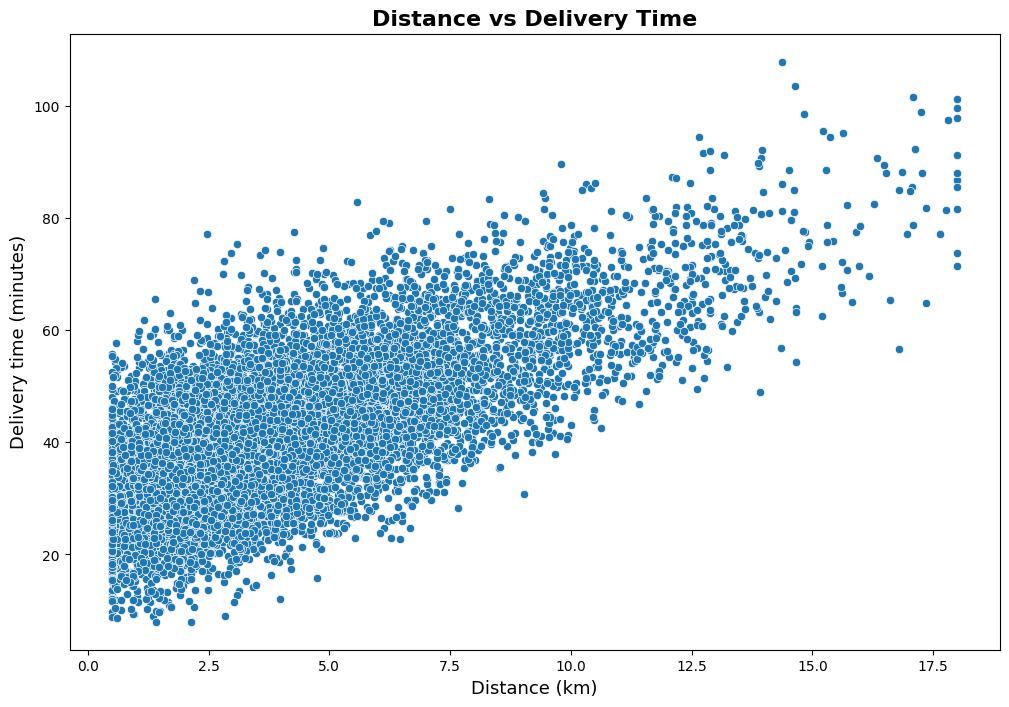

In [110]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=df, x="distance_km", y="delivery_minutes")

plt.xlabel("Distance (km)", fontsize=13)
plt.ylabel("Delivery time (minutes)", fontsize=13)
plt.title("Distance vs Delivery Time", fontsize=16, fontweight='bold')
plt.show()

# Traffic vs Delivery Time

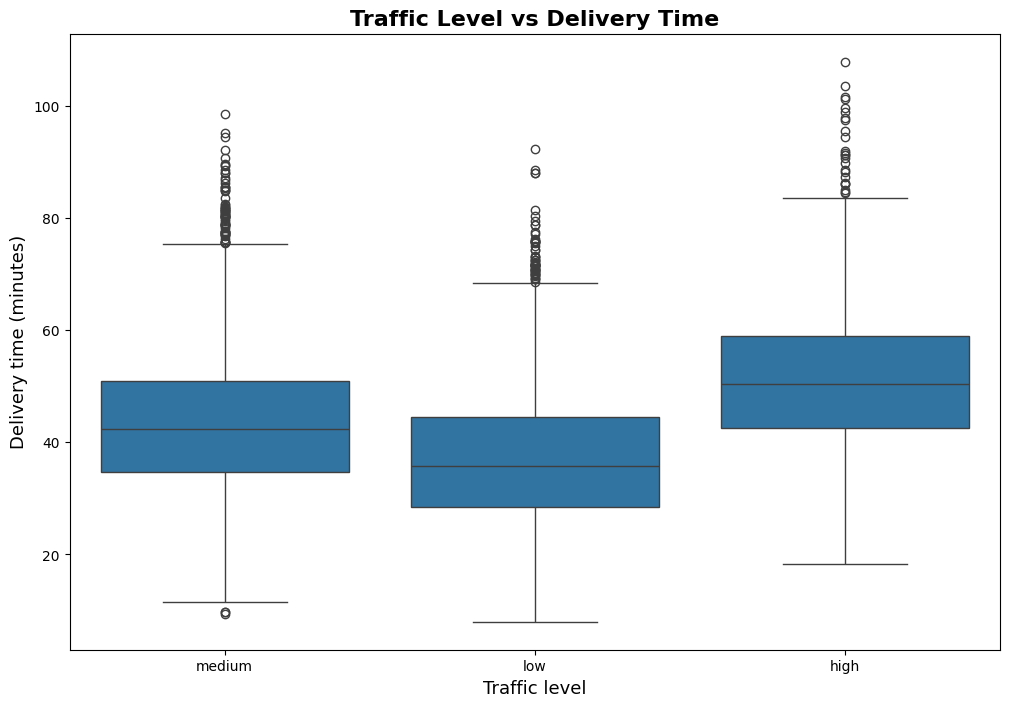

In [111]:
plt.figure(figsize=(12,8))
sns.boxplot(data=df, x="traffic_level", y="delivery_minutes")

plt.xlabel("Traffic level", fontsize=13)
plt.ylabel("Delivery time (minutes)", fontsize=13)
plt.title("Traffic Level vs Delivery Time", fontsize=16, fontweight='bold')
plt.show()

# Weather vs Delivery Time

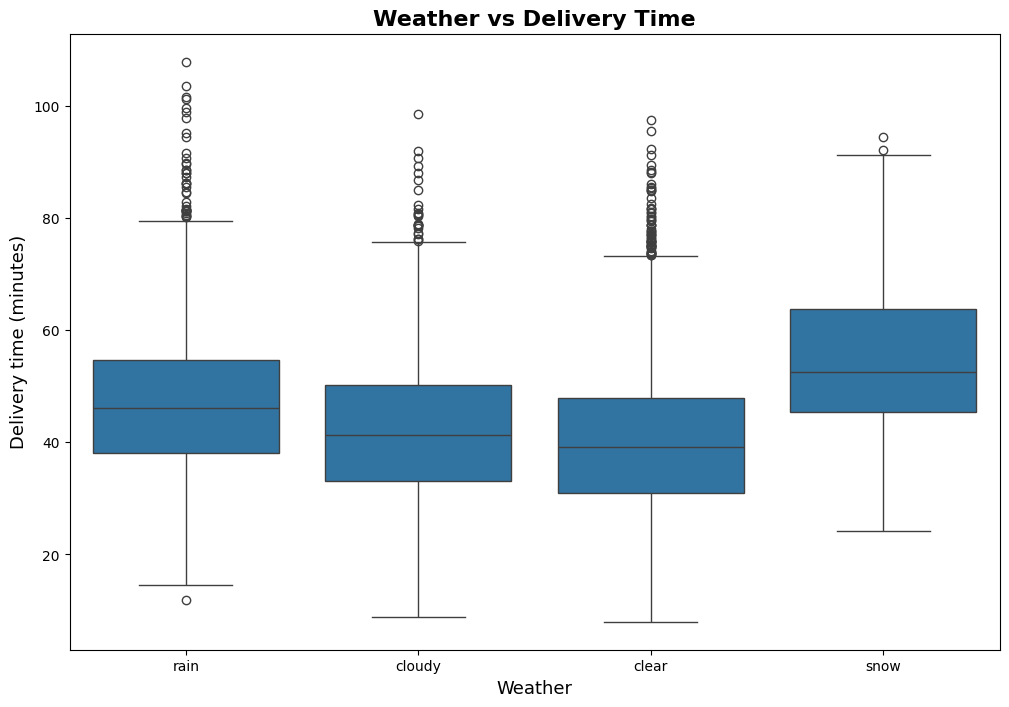

In [112]:
plt.figure(figsize=(12,8))
sns.boxplot(data=df, x="weather", y="delivery_minutes")

plt.xlabel("Weather", fontsize=13)
plt.ylabel("Delivery time (minutes)", fontsize=13)
plt.title("Weather vs Delivery Time", fontsize=16, fontweight='bold')
plt.show()

# Preparation Time vs Delivery Time

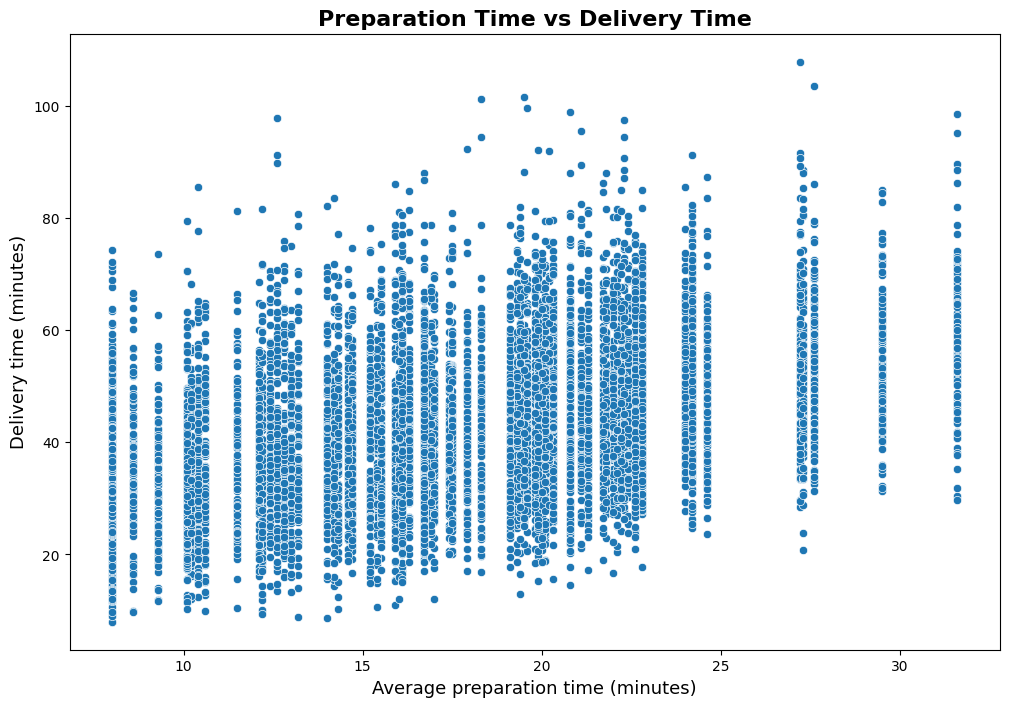

In [113]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=df, x="avg_prep_minutes", y="delivery_minutes")

plt.xlabel("Average preparation time (minutes)", fontsize=13)
plt.ylabel("Delivery time (minutes)", fontsize=13)
plt.title("Preparation Time vs Delivery Time", fontsize=16, fontweight='bold')
plt.show()

# Courier Experience vs Delivery Time

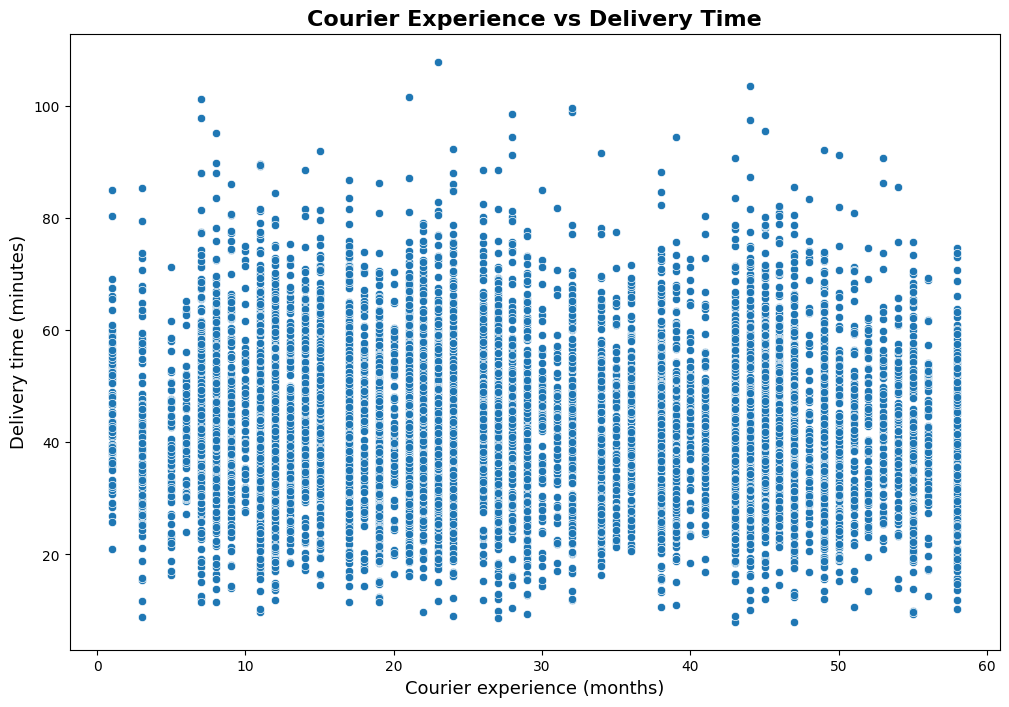

In [114]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=df, x="experience_months", y="delivery_minutes")

plt.xlabel("Courier experience (months)", fontsize=13)
plt.ylabel("Delivery time (minutes)", fontsize=13)
plt.title("Courier Experience vs Delivery Time", fontsize=16, fontweight='bold')
plt.show()

# Linear Regression prediction vs HistGradientBoosting prediction

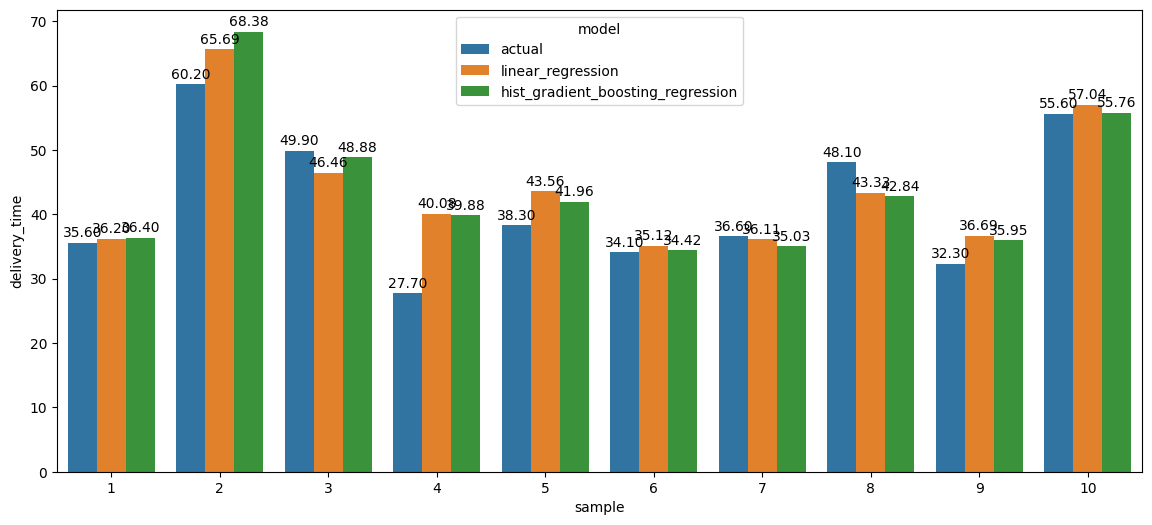

In [115]:
plt.figure(figsize=(14,6))
comparison = pd.DataFrame({
    "sample": range(1, 11),
    "actual": y_val[:10],
    "linear_regression": lr_preds[:10],
    "hist_gradient_boosting_regression": hgbr_preds[:10]
})
melted_df = comparison.melt(id_vars="sample", var_name="model", value_name="delivery_time")
ax = sns.barplot(data=melted_df, x="sample", y="delivery_time", hue="model")
for container in ax.containers:
    ax.bar_label(container,fontsize=10, fmt='%.2f', padding=2)

# Task 34. Residual Analysis

In [116]:
hgbr_residuals = y_val - hgbr_preds
print(hgbr_residuals)
print("Maximum residual:", hgbr_residuals.max())
print("Minimum residual:", hgbr_residuals.min())
print("Mean residual:", hgbr_residuals.mean())

7000    -0.799086
7001    -8.182601
7002     1.015551
7003   -12.181545
7004    -3.658379
          ...    
8495     3.232026
8496     3.324121
8497     6.783921
8498    -3.099452
8499    -1.320776
Name: delivery_minutes, Length: 1500, dtype: float64
Maximum residual: 18.249541703867877
Minimum residual: -12.181545448153752
Mean residual: 0.46139185143792094


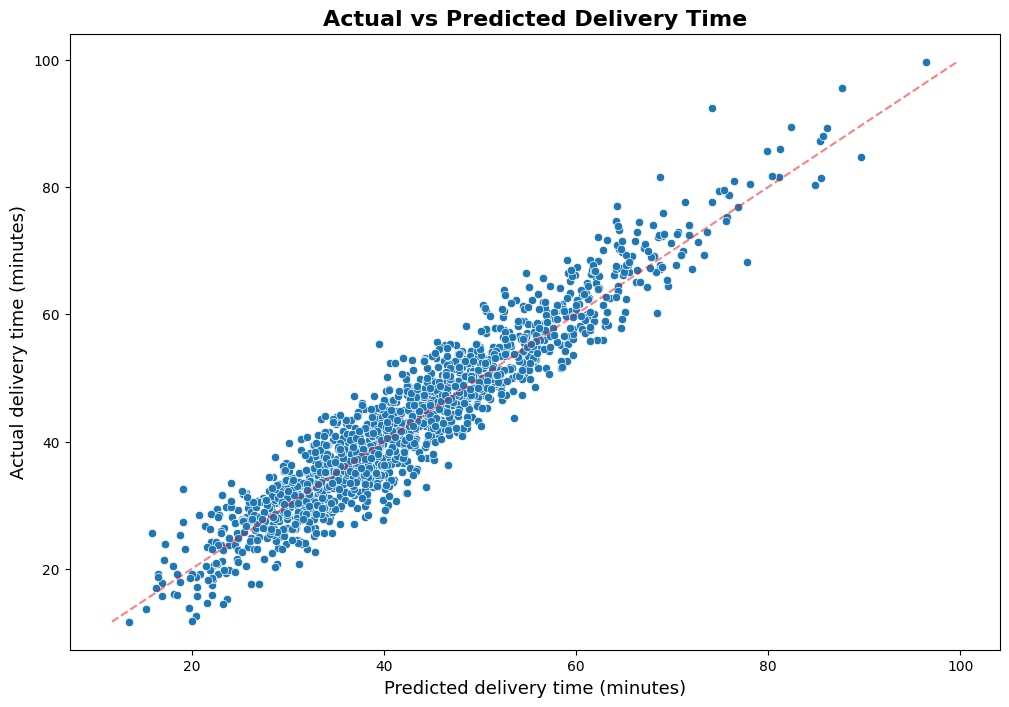

In [117]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x=hgbr_preds, y=y_val)

plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], "--", c="r", alpha=0.5)

plt.xlabel("Predicted delivery time (minutes)", fontsize=13)
plt.ylabel("Actual delivery time (minutes)", fontsize=13)
plt.title("Actual vs Predicted Delivery Time", fontsize=16, fontweight='bold')
plt.savefig("E:/Python/delivery_eta_project/images/actual_vs_predicted.png")
plt.show()

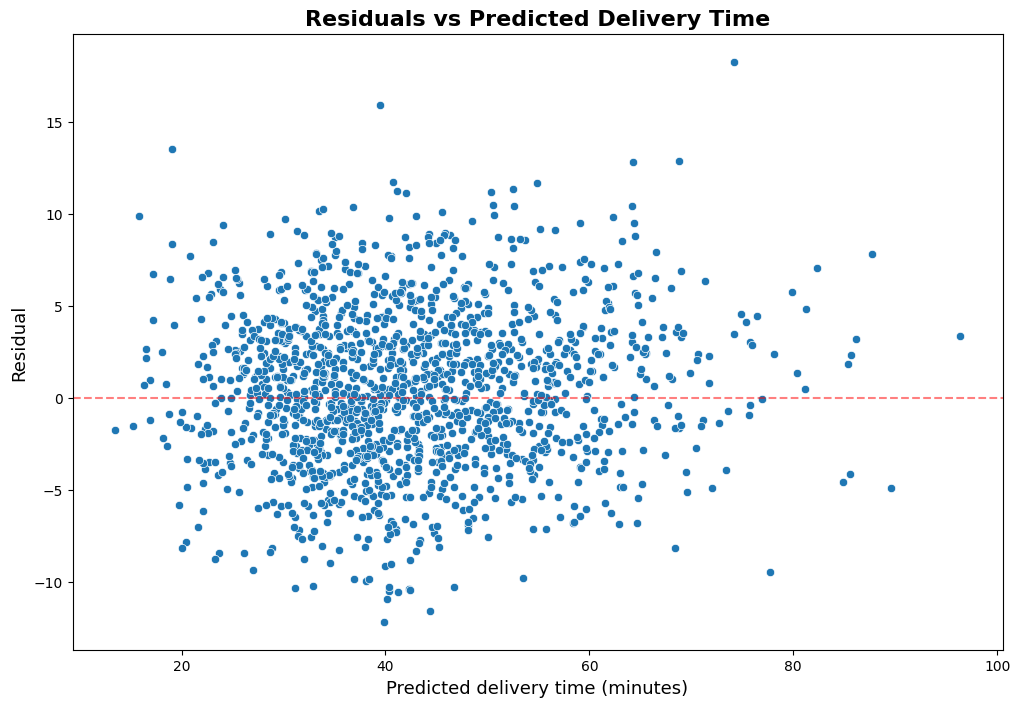

In [118]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x=hgbr_preds, y=hgbr_residuals)

plt.axhline(0, ls="--", c="r", alpha=0.5)

plt.xlabel("Predicted delivery time (minutes)", fontsize=13)
plt.ylabel("Residual", fontsize=13)
plt.title("Residuals vs Predicted Delivery Time", fontsize=16, fontweight='bold')
plt.savefig("E:/Python/delivery_eta_project/images/residuals.png")
plt.show()

# Task 35. Analyze the Largest Prediction Errors

In [119]:
top_5 = abs(y_val - hgbr_preds).nlargest(5)
top_5

8074    18.249542
8144    15.887926
7654    13.514700
7981    12.843769
7419    12.781254
Name: delivery_minutes, dtype: float64

In [120]:
ind = top_5.index
df.loc[ind]

,order_id,distance_km,items_count,order_amount,weather,traffic_level,order_ts,delivery_minutes,date,restaurant_id,...,restaurant_previous_orders_count,restaurant_historical_avg_delivery,courier_previous_orders_count,courier_historical_avg_delivery,is_peak_hour,month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
8074,1706,17.12,4,52.48,clear,low,2026-05-24 19:00:00,92.4,2026-05-24,31,...,100,40.718000,69,46.855072,False,5,-0.965926,0.258819,-2.449294e-16,1.000000
8144,1220,0.50,5,43.48,clear,high,2026-05-26 01:00:00,55.4,2026-05-26,44,...,93,52.800000,74,42.313514,True,5,0.258819,0.965926,9.749279e-01,-0.222521
7654,956,0.97,6,13.12,clear,medium,2026-05-16 20:00:00,32.6,2026-05-16,2,...,97,32.578351,72,41.559722,False,5,-0.866025,0.500000,-7.818315e-01,0.623490
7981,9728,7.50,2,39.05,rain,high,2026-05-22 21:00:00,81.6,2026-05-22,12,...,94,45.341489,70,43.692857,False,5,-0.707107,0.707107,-9.749279e-01,-0.222521
7419,6114,16.95,8,41.82,clear,low,2026-05-12 16:00:00,77.1,2026-05-12,56,...,109,39.369725,38,44.394737,False,5,-0.866025,-0.500000,9.749279e-01,-0.222521


In [121]:
hgbr_preds_series = pd.Series(
    hgbr_preds,
    index=y_val.index
)

actual_delivery_time = y_val.loc[ind]
predicted_delivery_time = hgbr_preds_series.loc[ind]
print("actual_delivery_time:\n", actual_delivery_time)
print("predicted_delivery_time:\n", predicted_delivery_time)

actual_delivery_time:
 8074    92.4
8144    55.4
7654    32.6
7981    81.6
7419    77.1
Name: delivery_minutes, dtype: float64
predicted_delivery_time:
 8074    74.150458
8144    39.512074
7654    19.085300
7981    68.756231
7419    64.318746
dtype: float64


# Task 36. Permutation Feature Importance

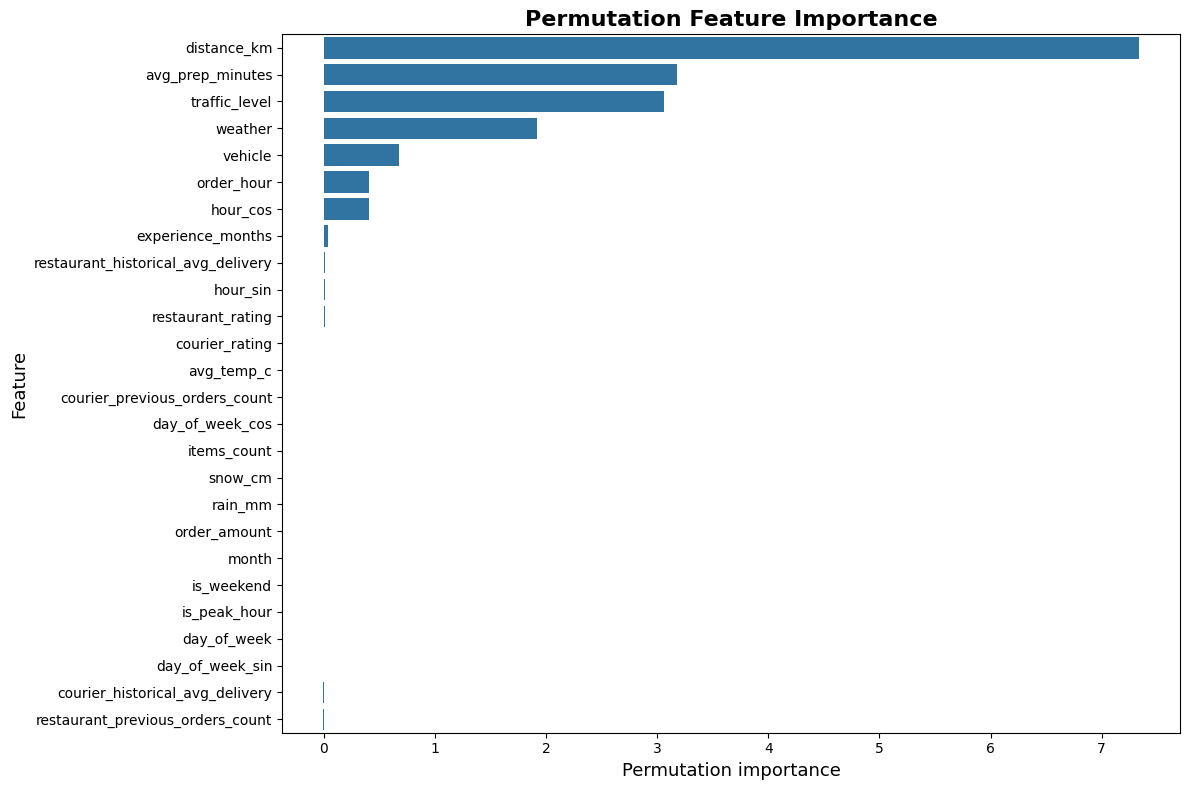

In [122]:
plt.figure(figsize=(12, 8))
feature_names = X_val.columns
perm = permutation_importance(best_hgbr, X_val, y_val, scoring="neg_mean_absolute_error", n_repeats=20, random_state=42)
perm_df = pd.DataFrame({
    "feature": feature_names,
    "importance": perm.importances_mean
}).sort_values(by= 'importance', ascending = False)

sns.barplot(data= perm_df, x= "importance", y= "feature")

plt.title("Permutation Feature Importance", fontsize=16, fontweight="bold")

plt.xlabel("Permutation importance", fontsize=13)
plt.ylabel("Feature", fontsize=13)

plt.tight_layout()
plt.show()

# BLOCK 12. Final Model

# Task 37. Select the Final Model

In [123]:
# Based on task 32 the best model is the tuned HistGradientBoostingRegressor.
# It achieved the lowest RMSE, MAE, and MAPE values on the validation set,
# as well as the highest R² value among the evaluated models.

In [124]:
final_model = best_hgbr

# Task 38. Final Test Evaluation

In [125]:
final_test_preds = final_model.predict(X_test)

final_test_RMSE = root_mean_squared_error(y_test,final_test_preds)
final_test_MAE = mean_absolute_error(y_test, final_test_preds)
final_test_r2 = r2_score(y_test, final_test_preds)
final_test_MAPE = mean_absolute_percentage_error(y_test, final_test_preds) * 100

final_test_metrics = pd.DataFrame({
    "root_mean_squared_error": final_test_RMSE,
    "mean_absolute_error": final_test_MAE,
    "r2_score": final_test_r2,
    "mean_absolute_percentage_error": final_test_MAPE
}, index=["Final Model - Test"])
final_test_metrics

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Final Model - Test,4.322854,3.418012,0.898719,8.926907


# Task 39. Compare Validation and Test Performance

In [126]:
pd.concat([tuned_hgbr_metrics, final_test_metrics])

,root_mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
Tuned HistGradientBoostingRegressor,4.166115,3.326782,0.905418,8.576781
Final Model - Test,4.322854,3.418012,0.898719,8.926907


In [127]:
comparison = pd.DataFrame({
    "Validation": tuned_hgbr_metrics.iloc[0],
    "Test": final_test_metrics.iloc[0]
})

comparison["Difference"] = round((comparison["Test"] - comparison["Validation"]) * 100, 2).apply(lambda x: f"{x}%" if x < 0 else f"+{x}%")
comparison

,Validation,Test,Difference
root_mean_squared_error,4.166115,4.322854,+15.67%
mean_absolute_error,3.326782,3.418012,+9.12%
r2_score,0.905418,0.898719,-0.67%
mean_absolute_percentage_error,8.576781,8.926907,+35.01%


# Task 40. Analyze Final Model Test Errors

In [128]:
test_residuals = y_test - final_test_preds
print(test_residuals)
print("Maximum residual:", test_residuals.max())
print("Minimum residual:", test_residuals.min())
print("Mean residual:", test_residuals.mean())

8500   -5.279663
8501    9.649390
8502    2.303181
8503   -9.127365
8504    3.545045
          ...   
9995   -1.055483
9996   -8.554568
9997   -2.776408
9998    6.208606
9999   -2.615583
Name: delivery_minutes, Length: 1500, dtype: float64
Maximum residual: 15.954768866369307
Minimum residual: -13.82204175510224
Mean residual: 0.8677579867405839


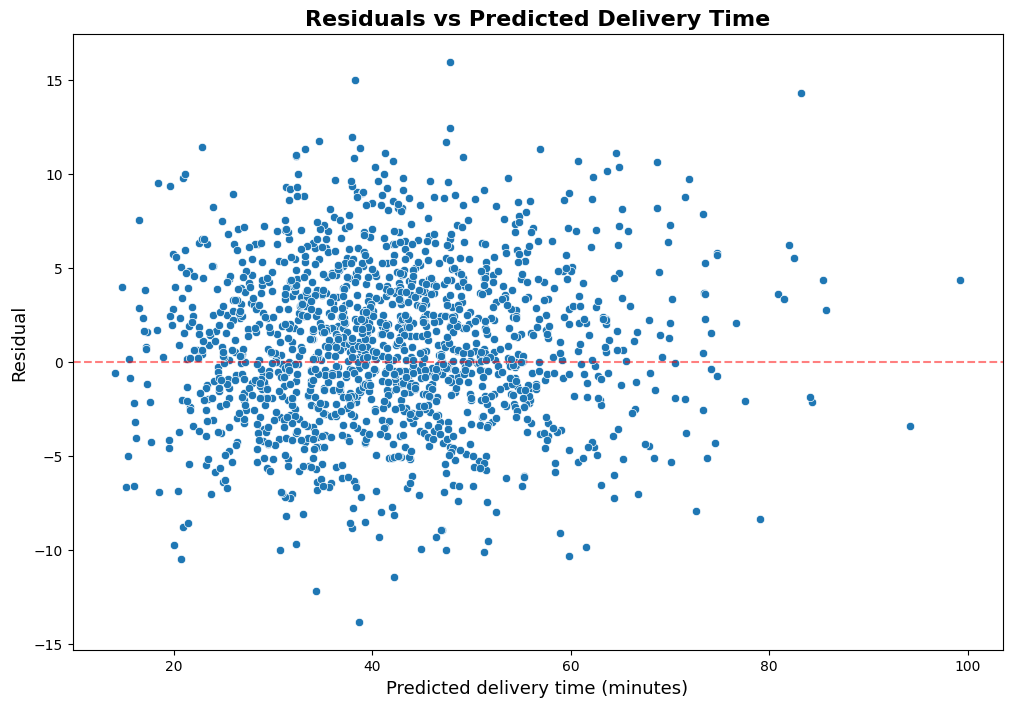

In [129]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x=final_test_preds, y=test_residuals)

plt.axhline(0, ls="--", c="r", alpha=0.5)

plt.xlabel("Predicted delivery time (minutes)", fontsize=13)
plt.ylabel("Residual", fontsize=13)
plt.title("Residuals vs Predicted Delivery Time", fontsize=16, fontweight='bold')
plt.show()

In [130]:
top_5 = abs(test_residuals).nlargest(5)
top_5

9442    15.954769
8739    15.001921
9576    14.272794
9648    13.822042
9284    12.426364
Name: delivery_minutes, dtype: float64

In [131]:
ind = top_5.index
test_df.loc[ind]

,order_id,distance_km,items_count,order_amount,weather,traffic_level,order_ts,delivery_minutes,date,restaurant_id,...,restaurant_previous_orders_count,restaurant_historical_avg_delivery,courier_previous_orders_count,courier_historical_avg_delivery,is_peak_hour,month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
9442,5773,5.97,6,12.33,clear,medium,2026-06-19 02:00:00,63.8,2026-06-19,22,...,115,45.548696,80,44.735000,False,6,0.500000,8.660254e-01,-0.974928,-0.222521
8739,3832,7.98,8,10.03,clear,low,2026-06-06 04:00:00,53.3,2026-06-06,58,...,121,40.564463,79,39.437975,True,6,0.866025,5.000000e-01,-0.781831,0.623490
9576,3395,17.81,5,66.21,clear,high,2026-06-22 06:00:00,97.5,2026-06-22,72,...,119,51.026050,88,41.365909,True,6,1.000000,6.123234e-17,0.781831,0.623490
9648,3650,0.50,8,6.26,clear,high,2026-06-23 14:00:00,24.9,2026-06-23,59,...,123,41.200000,91,44.548352,False,6,-0.500000,-8.660254e-01,0.974928,-0.222521
9284,1389,1.40,3,13.96,rain,high,2026-06-16 06:00:00,60.3,2026-06-16,11,...,114,47.238596,69,49.085507,True,6,1.000000,6.123234e-17,0.974928,-0.222521


In [132]:
final_preds_series = pd.Series(
    final_test_preds,
    y_test.index
)

actual_delivery_time = y_test.loc[ind]
predicted_delivery_time = final_preds_series.loc[ind]
print("actual_delivery_time:\n", actual_delivery_time)
print("predicted_delivery_time:\n", predicted_delivery_time)

actual_delivery_time:
 9442    63.8
8739    53.3
9576    97.5
9648    24.9
9284    60.3
Name: delivery_minutes, dtype: float64
predicted_delivery_time:
 9442    47.845231
8739    38.298079
9576    83.227206
9648    38.722042
9284    47.873636
dtype: float64


# Task 41. Save Final Model

In [133]:
joblib.dump(final_model, "E:/Python/delivery_eta_project/models/final_model.pkl")

['E:/Python/delivery_eta_project/models/final_model.pkl']

In [134]:
df.to_csv("E:/Python/delivery_eta_project/data/processed/final_ml_dataset.csv", index=False)

In [135]:
joblib.dump(lr, "E:/Python/delivery_eta_project/models/LinearRegression.pkl")
joblib.dump(Rg, "E:/Python/delivery_eta_project/models/Ridge.pkl")
joblib.dump(Lo, "E:/Python/delivery_eta_project/models/Lasso.pkl")
joblib.dump(EN, "E:/Python/delivery_eta_project/models/ElasticNet.pkl")
joblib.dump(hgbr, "E:/Python/delivery_eta_project/models/HistGradientBoosting-default.pkl")

['E:/Python/delivery_eta_project/models/HistGradientBoosting-default.pkl']

In [136]:
print(num_cols.tolist())
print(cat_cols.tolist())
print(bool_cols.tolist())

['distance_km', 'items_count', 'order_amount', 'avg_prep_minutes', 'restaurant_rating', 'avg_temp_c', 'rain_mm', 'snow_cm', 'experience_months', 'courier_rating', 'order_hour', 'day_of_week', 'restaurant_previous_orders_count', 'restaurant_historical_avg_delivery', 'courier_previous_orders_count', 'courier_historical_avg_delivery', 'month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']
['weather', 'traffic_level', 'vehicle']
['is_weekend', 'is_peak_hour']
